# 01 — Constraints and geometry

The study starts from the constraints file (`constraints/checkers_rot3u.json`): the board, the piece
diameter, what the gripper needs, the printer's rules and the physics ranges. Every number there has a
note saying where it came from. This notebook builds the three piece families from those numbers,
draws them, and runs the print and robot checks (DD-STACK SP-1 to SP-5).

In [1]:
# Setup: works from this folder whether or not the package was pip-installed
import sys, os, json
HERE = os.path.abspath("")
ROOT = os.path.dirname(HERE) if os.path.basename(HERE) == "notebooks" else HERE
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
import numpy as np
import matplotlib.pyplot as plt
import stackpieces
print("stackpieces", stackpieces.__version__, "| folder", os.path.relpath(ROOT))
CONSTRAINTS = os.path.join(ROOT, "constraints", "checkers_rot3u.json")
REFERENCE = os.path.join(ROOT, "results", "reference", "results.json")
c = json.load(open(CONSTRAINTS))
QUICK = True   # True: a few minutes, coarse. False: the full reference run (tens of minutes).

stackpieces 0.1.0 | folder ..


In [2]:
from stackpieces.geometry import PRESETS, make_piece, checks, summary, volume_exact
for group in ("board", "piece", "gripper", "goal", "printer"):
    print(group, {k: v for k, v in c[group].items() if not k.startswith("_")})

board {'square_mm': 25.4, 'pieces_on_diagonals_only': True}
piece {'diameter_mm': 25.0, 'stack_of': 2}
gripper {'grip_band_min_mm': 10.0, 'grip_band_max_mm': 15.0, 'finger_thickness_mm': None, 'placement_error': {'model': 'uniform', 'resolution_mm': 10.0}}
goal {'target_offset_fraction': 0.5, 'target_offset_of': 'diameter', 'max_height_mm': 25.0, 'seat_rate_required': 0.8}
printer {'name': 'Bambu X2D, PLA, 0.4 nozzle', 'layer_mm': 0.2, 'overhang_max_deg': 45.0, 'bridge_max_mm': 10.0, 'min_wall_mm': 0.8, 'hole_undersize_mm': [0.1, 0.5], 'od_undersize_mm': 0.2}


## The three families

* **shoulder** (S40 is one): grip band, flat shoulder, cone, matching socket underneath. The piece above
  seats with its bottom rim flat on the shoulder.
* **nesting** (N35): the cone starts at the full diameter and the socket nests up inside the piece's own
  cone, like stacking cups. Steeper cones without a taller band.
* **cylinder**: the control. It stacks flat but never centers.

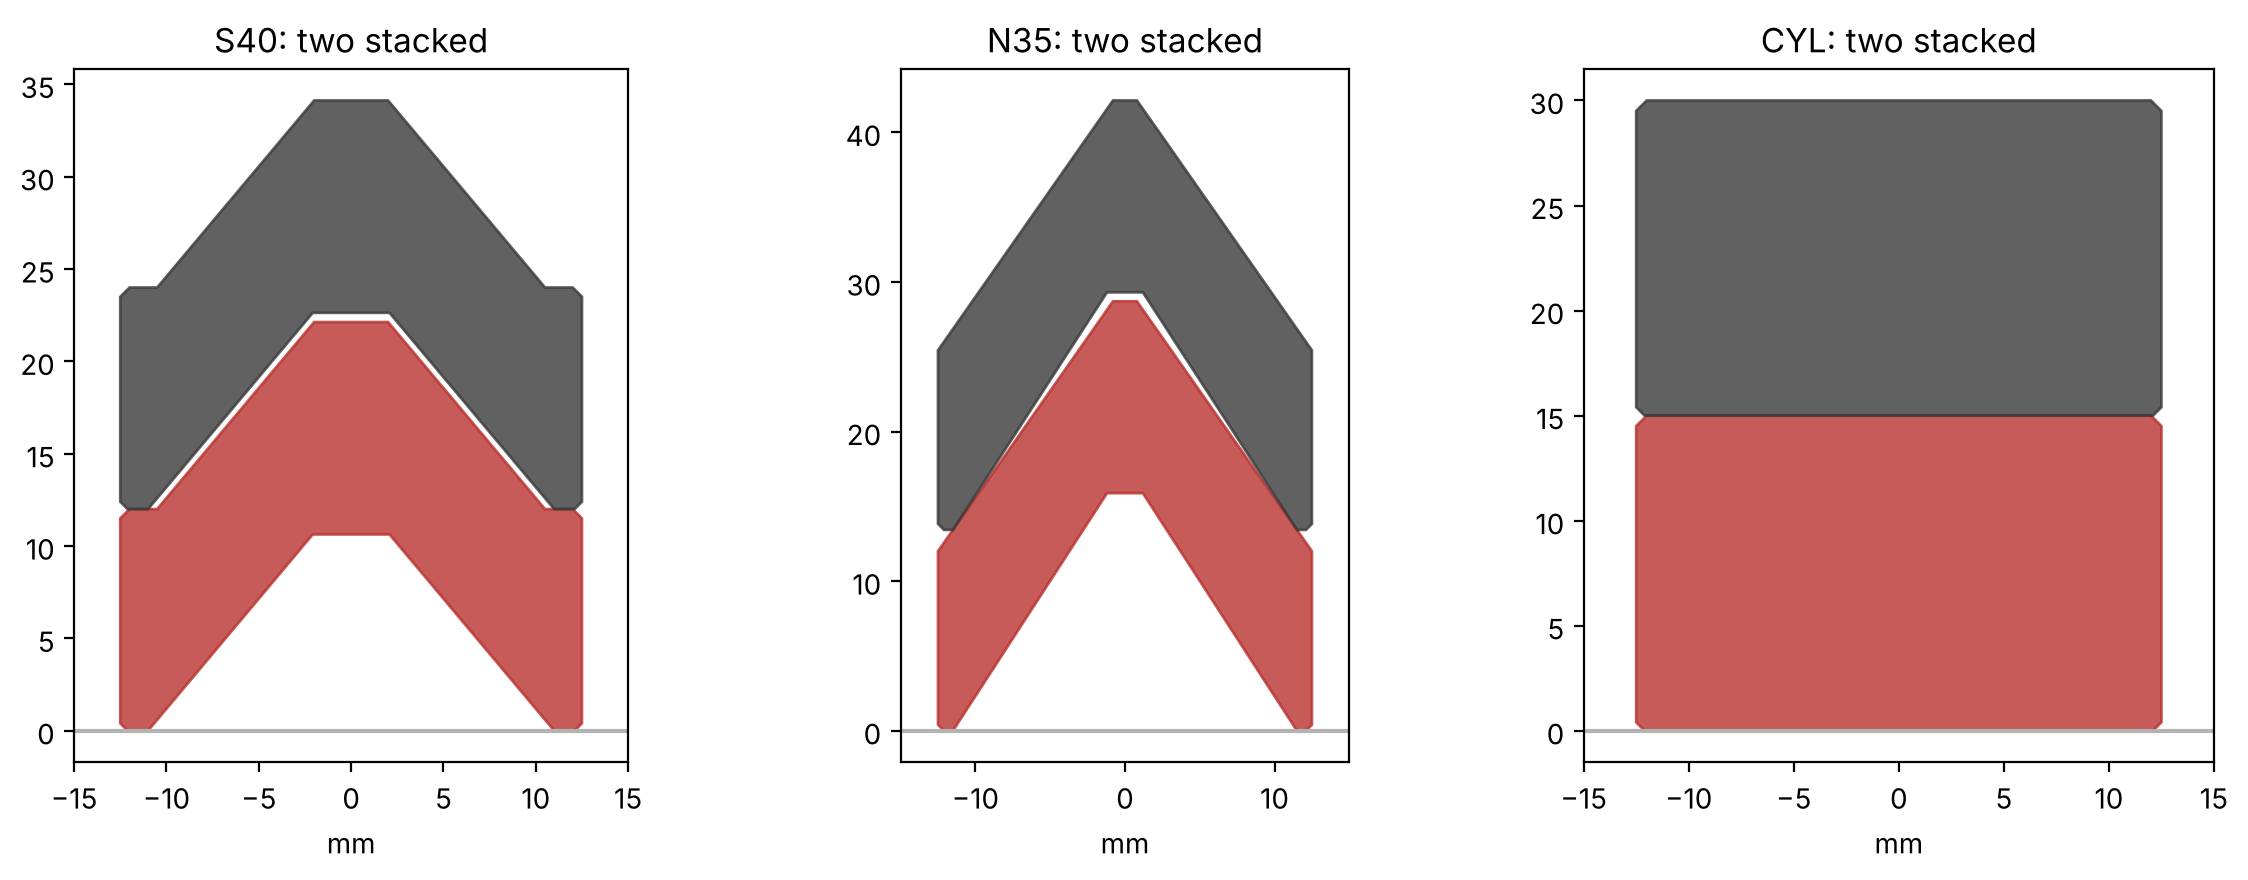

In [3]:
pieces = {k: make_piece(p, c["physics"]["density_g_per_mm3"]) for k, p in PRESETS.items()}
fig, axs = plt.subplots(1, 3, figsize=(12, 4.5))
for ax, (k, g) in zip(axs, pieces.items()):
    for z0, col in ((0, "#b8322f"), (g["seat"], "#3a3a3a")):
        pr = g["profile"]
        pts = pr + [(-r, z) for r, z in reversed(pr)]
        ax.fill([x for x, _ in pts], [z + z0 for _, z in pts], color=col, alpha=0.8)
    ax.axhline(0, color="0.7"); ax.set_aspect("equal"); ax.set_title(f"{k}: two stacked")
    ax.set_xlabel("mm"); ax.set_xlim(-15, 15)
plt.tight_layout(); plt.show()

In [4]:
import pandas as pd  # WinPython includes pandas; only used for tables here
rows = {k: summary(g) for k, g in pieces.items()}
pd.DataFrame(rows).round(2)

,S40,N35,CYL
R,12.50,12.50,12.50
H,22.13,28.71,15.00
band_h,12.00,12.00,15.00
h,10.13,16.71,0.00
rt,2.00,0.80,0.00
Rm,11.00,11.50,0.00
rs,2.08,1.20,NaN
hs,10.63,15.88,NaN
seat,12.00,13.43,15.00
king_h,34.13,42.14,30.00


## Volume check

The mass properties come from integrating the half-section on a 0.05 mm grid (the browser tool uses the
same grid). The exact volume of the revolved polygon (Pappus) checks it; S40's exact volume also matches
the SolidWorks part in `cad/checker_s40`, 5,659.463 mm³.

In [5]:
for k, g in pieces.items():
    ex = volume_exact(g["profile"])
    print(f"{k}: grid {g['V']:.2f} mm3, exact {ex:.3f} mm3, difference {100 * (g['V'] - ex) / ex:+.3f} %")

S40: grid 5657.70 mm3, exact 5659.465 mm3, difference -0.031 %
N35: grid 6351.43 mm3, exact 6351.639 mm3, difference -0.003 %
CYL: grid 7345.47 mm3, exact 7347.205 mm3, difference -0.024 %


## Print and robot checks

`finger_room` fails until the gripper's finger thickness is measured (it is `null` in the constraints): the gap
between pieces on diagonal neighbor squares is shown so it can be compared by hand. N35 fails the rim check:
its flat ring on the bed is 0.6 mm wide after the 0.4 mm chamfer, under the printer's 0.8 mm minimum wall.

In [6]:
pd.DataFrame({k: {x["id"]: ("pass " if x["ok"] else "FAIL ") + str(x["value"]) for x in checks(g, c)}
              for k, g in pieces.items()})

,S40,N35,CYL
overhang,pass 40.0,pass 32.966,NaN
bridge,pass 4.161,pass 2.4,NaN
roof,pass 1.37,pass 12.828,NaN
rim,pass 1.1,FAIL 0.6,pass 12.1
grip_band_min,pass 12.0,pass 12.0,pass 15.0
grip_band_max,pass 12.0,pass 12.0,pass 15.0
height,pass 22.13,FAIL 28.709,pass 15.0
finger_room,FAIL 10.921,FAIL 10.921,FAIL 10.921
shell_wall,NaN,pass 7.03,NaN


## Printed surfaces

With 0.2 mm layers, each layer's edge is a rounded bead that reaches the CAD surface at mid-layer, so the cone
and the socket become staircases of ridges (DD-STACK SP-5). The trigonometric staircase model gives the
roughness Ra = layer/4 · cos(inclination).

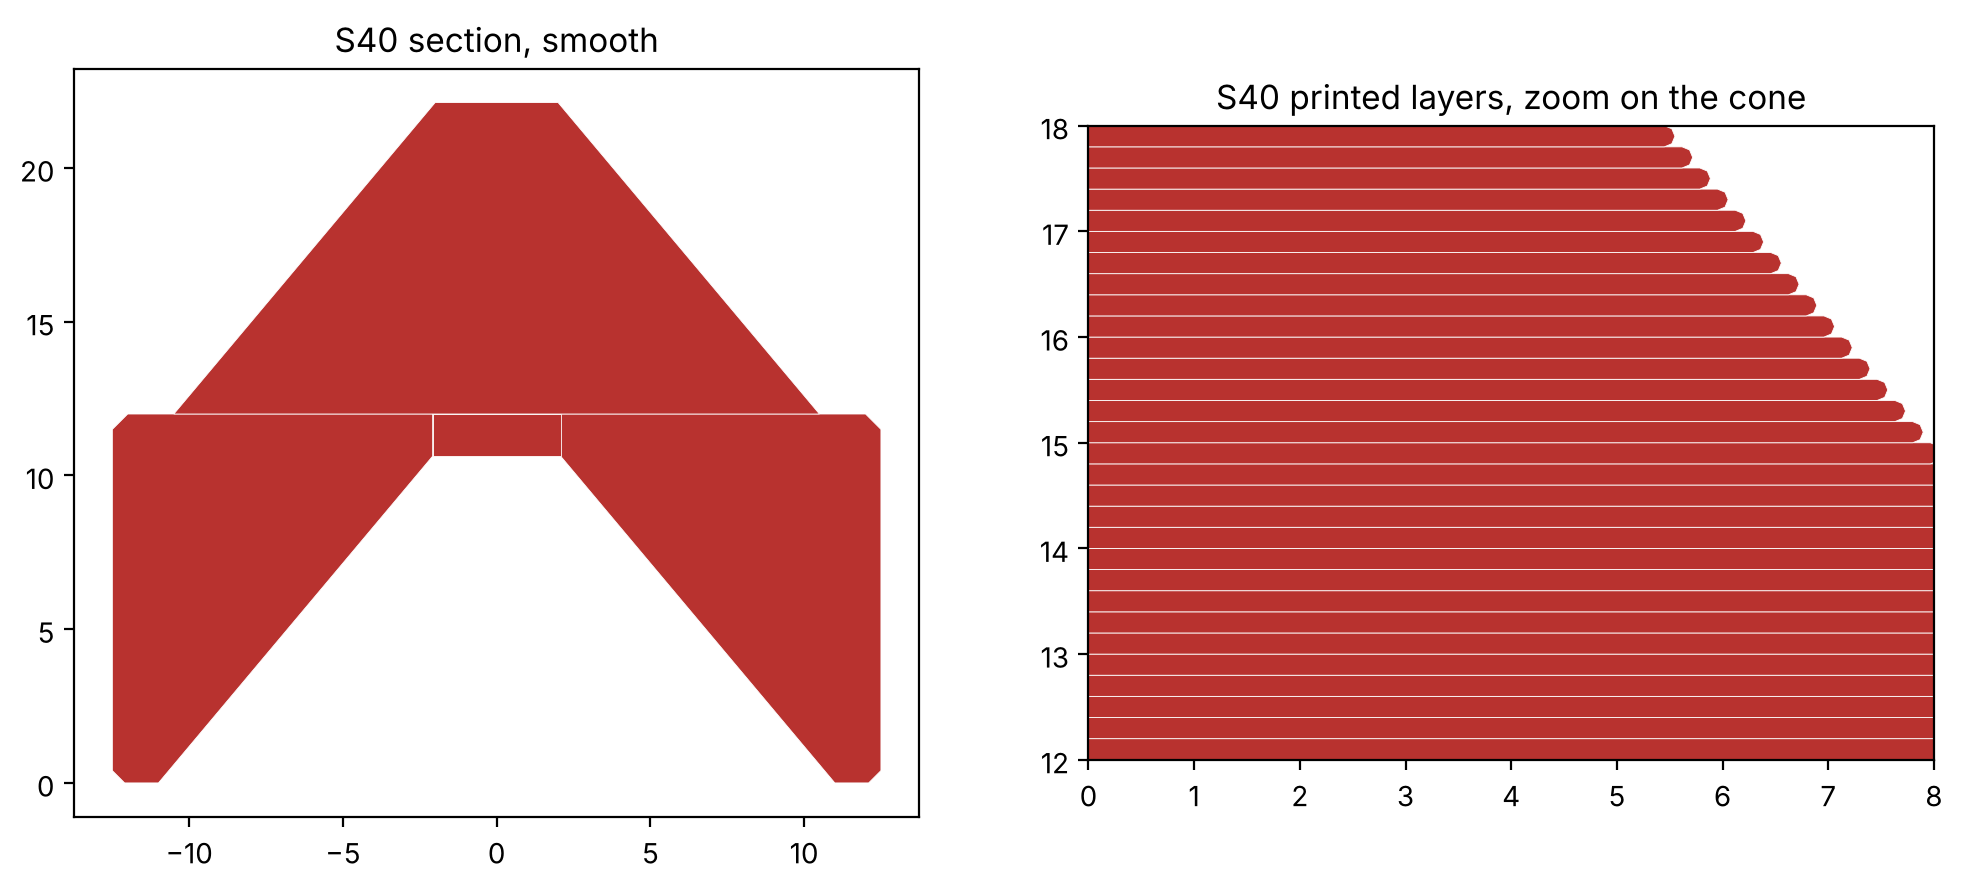

Ra on the 40 deg cone (50 deg from the bed): 32 um


In [7]:
from stackpieces.surface import section, ra_staircase
g = pieces["S40"]
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, (v, lim) in zip(axs, (("smooth", None), ("layered", (0, 8, 12, 18)))):
    for P in section(g, v, c["printer"]["layer_mm"]):
        ax.fill([x for x, _ in P], [z for _, z in P], color="#b8322f", ec="w", lw=0.3)
    ax.set_aspect("equal"); ax.set_title(f"S40 section, {v}")
    if lim: ax.set_xlim(lim[0], lim[1]); ax.set_ylim(lim[2], lim[3]); ax.set_title("S40 printed layers, zoom on the cone")
plt.show()
print(f"Ra on the 40 deg cone (50 deg from the bed): {1000 * ra_staircase(0.2, 50):.0f} um")